## Start here — Google Colab
Upload this entire unzipped folder to **My Drive**, open this notebook with Google Colaboratory, and choose **Runtime → Run all**. Approve the Drive connection when prompted. The next cell finds the course and prepares its dependencies automatically. No path editing is needed.
Run notebooks **00 → 01 → 02 → 03 → 04**. Use a fresh runtime for this course. CPU is sufficient. The first setup can take a few minutes. Results are saved in the same Drive folder.


In [ ]:
# Connect Drive and prepare this course automatically before importing lesson libraries.
from pathlib import Path
import os
import sys
import json
import subprocess
import importlib.metadata as package_metadata

COURSE_ID = 'ground-truth-gym-l3-4.0'
MARKER = 'COURSE_PACKAGE.json'
try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    drive.mount('/content/drive')
    search_root = Path('/content/drive/MyDrive')
else:
    search_root = Path.cwd()


def find_course(root):
    matches = []
    for directory, subfolders, files in os.walk(root):
        subfolders[:] = [name for name in subfolders if not name.startswith('.') and name not in {'node_modules', '__pycache__'}]
        if MARKER in files:
            marker = Path(directory) / MARKER
            if json.loads(marker.read_text()).get('course_id') == COURSE_ID:
                matches.append(Path(directory))
                subfolders[:] = []
    if len(matches) != 1:
        raise RuntimeError('Keep one unzipped GroundTruth_Gym_L3 folder in My Drive, then run this cell again. Found: ' + str(len(matches)))
    return matches[0]

# Reuse this notebook's local directory, or discover its uploaded Drive folder.
local_marker = Path.cwd() / MARKER
if drive is None and local_marker.exists() and json.loads(local_marker.read_text()).get('course_id') == COURSE_ID:
    course_root = Path.cwd()
else:
    course_root = find_course(search_root)
os.chdir(course_root)

requirements = (course_root / 'requirements-colab.txt').read_text().splitlines()
requirements = [line.strip() for line in requirements if line.strip() and not line.startswith('#')]
if drive is not None:
    # Install to a runtime-local directory before any scientific library imports.
    # Keep Google Colab's own packages and Drive integration unchanged.
    dependency_dir = Path('/content/groundtruth_gym_dependencies')
    stamp = dependency_dir / 'course_requirements.json'
    if not stamp.exists() or json.loads(stamp.read_text()) != requirements:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', '--upgrade', '--target', str(dependency_dir), *requirements])
        stamp.write_text(json.dumps(requirements))
    sys.path.insert(0, str(dependency_dir))
    # A fresh course runtime avoids mixing pre-imported binary library versions.
    for distribution, module in [('numpy', 'numpy'), ('pandas', 'pandas'), ('scipy', 'scipy'), ('scikit-learn', 'sklearn'), ('matplotlib', 'matplotlib'), ('joblib', 'joblib')]:
        expected = next(line.split('==')[1] for line in requirements if line.startswith(distribution + '=='))
        loaded = sys.modules.get(module)
        if loaded is not None and getattr(loaded, '__version__', expected) != expected:
            raise RuntimeError('Please select Runtime > Disconnect and delete runtime, reconnect, and Run all. No path or package configuration is needed.')

for item in requirements:
    distribution, expected = item.split('==')
    actual = package_metadata.version(distribution)
    if actual != expected:
        raise RuntimeError(f'{distribution}: expected {expected}, found {actual}. Use a fresh Colab runtime and run this first cell.')

# Use a consistent single-thread execution policy across notebook runtimes.
for variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[variable] = '1'
print('Course ready:', course_root.name)
print('Data and results persist in your course folder. Run notebooks 00 → 01 → 02 → 03 → 04.')


# 01 — Can current member information support a purchase-propensity model?

### Before you start

Comfort with Python and pandas is sufficient. Prior knowledge of model pipelines is not required.

### What you will learn

- Connect eight tables to a member's business journey.
- Distinguish pre-decision features from new future purchases.
- Assess whether the historical population covers first-purchase, repeat-purchase and reactivation cases.
- Explain which labels are known, which remain unknown, and whether the evidence supports a limited comparison.

## Our Goal — Find likely future buyers across all PT histories

We have 1,200 eligible members and can send at most 1,000 promotions. We want to estimate each person's probability of making a **new PT package purchase within 30 days after the scoring decision**. A past purchase does not guarantee a new one; no past purchase does not mean no future demand.

**Who belongs?** Never-PT, currently active PT and lapsed PT members. All meet the case's permission and membership eligibility assumptions. PT status is a feature, not a filter.

**What can we know now?** Recent visits, classes, app engagement, enquiries, PT attendance and changing activity; plus profile, prior PT purchase count/recency and remaining sessions. These facts must already be available at the decision timestamp.

**What is the target?** New valid purchase = 1; no new valid purchase after a complete window and payment coverage = 0. Target is binary; the classifier estimates a probability between 0 and 1 for ranking. Old purchases never become this window's positive label.

**What happens after scoring?** Rank recipients, send messages, and optionally accept consultation bookings until 200 places are filled. A member may also buy directly. There is no required linear funnel through consultation for all purchases.

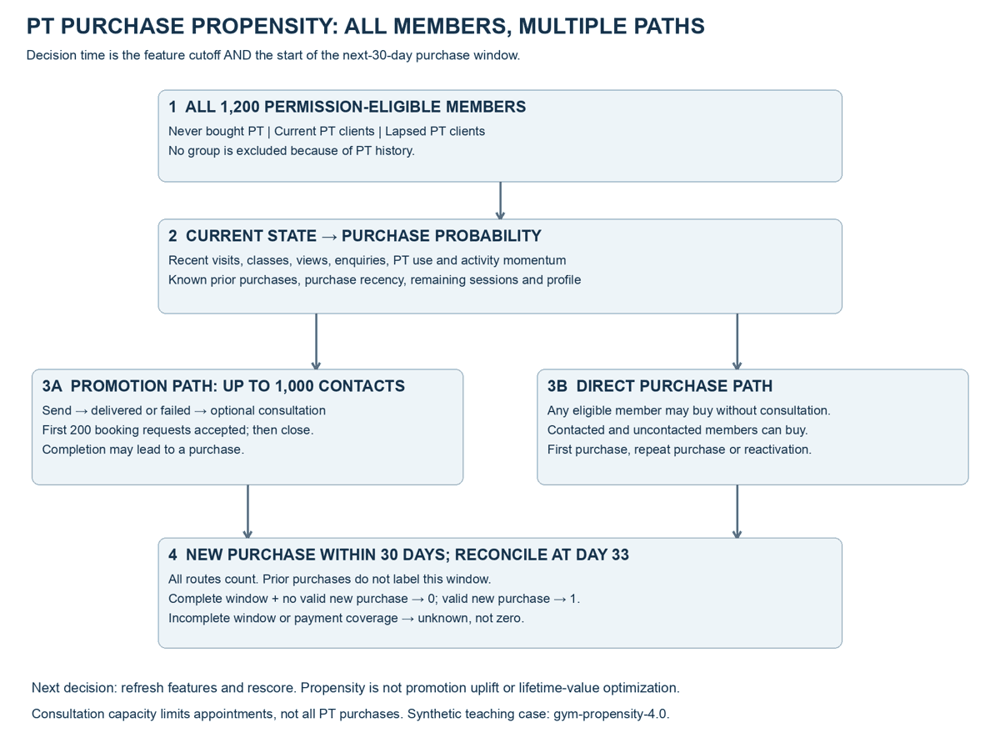

**Recurring use:** Refresh the features at the next decision and rescore the member. The same person may be a likely first buyer now and a likely repeat buyer later. This notebook evaluates one snapshot per member across separate time cohorts; it does not demonstrate lifetime optimization or repeat-message effects.

**Purchase propensity is not uplift:** Ranking likely buyers does not establish who will buy because of a promotion. Contact history is part of the historical policy; evaluation cannot substitute for a causal test.

### How to follow the data checks
Read the question and plan, inspect the annotated calculation and its figure/table, then read the takeaway. EDA-03/05 remain optional process references, not extra modeling stages.

### Takeaway — Our Goal
**The business decision sets the data checks.** Identify all eligible members, available decision-time information and complete future purchase outcomes before choosing a model.

## DATA-00 — What data have we received?

### The question
Before modeling, can these records describe members and their future outcomes?

### What to inspect
- Extracted June 1, 2025. Eight source tables and six decision cohorts.

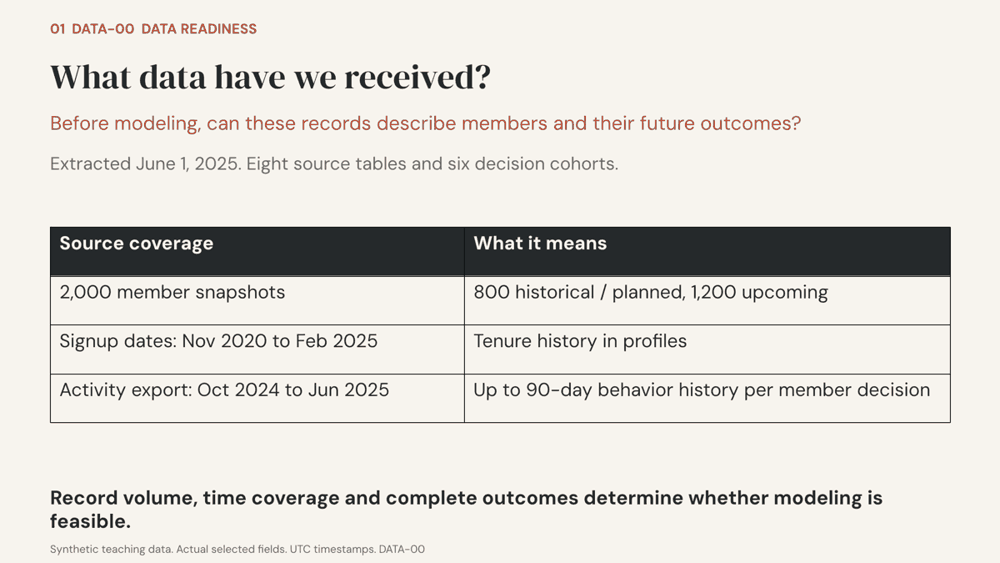

**What this means:** Record volume, time coverage and complete outcomes determine whether modeling is feasible.

## DATA-00A — Member decision snapshots

### The question
Who is the member at this decision?

### What to inspect
- 2,000 raw rows. One member at one decision snapshot. Signup dates describe tenure.
- Decision dates listed: 2025-01-01 to 2025-06-15 (includes planned cohorts).

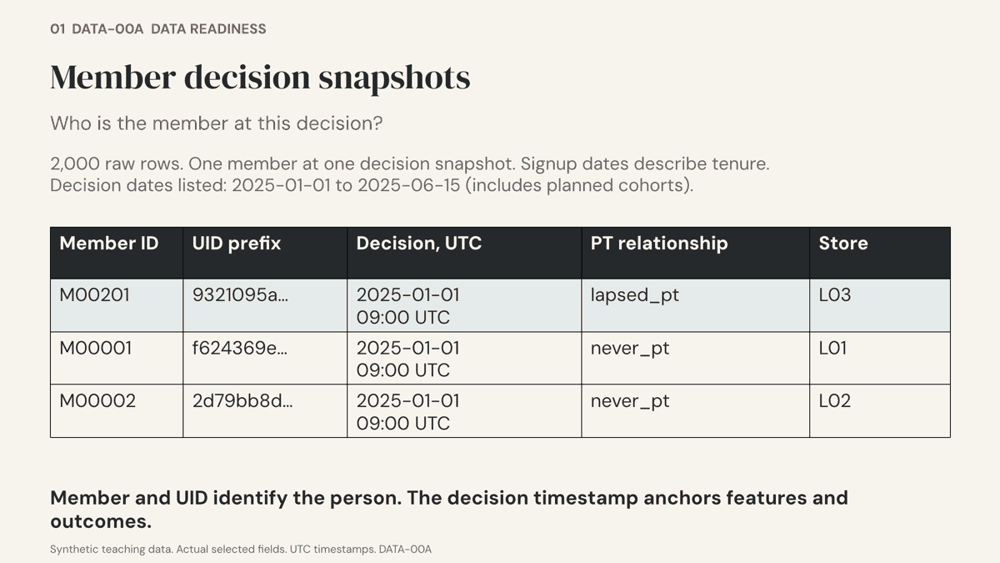

**What this means:** Member and UID identify the person. The decision timestamp anchors features and outcomes.

## DATA-00B — Store context

### The question
Which store and city provide context?

### What to inspect
- 6 raw rows. One store per row. Six stores across three cities.
- Context: Static store dimension; no event-time field.

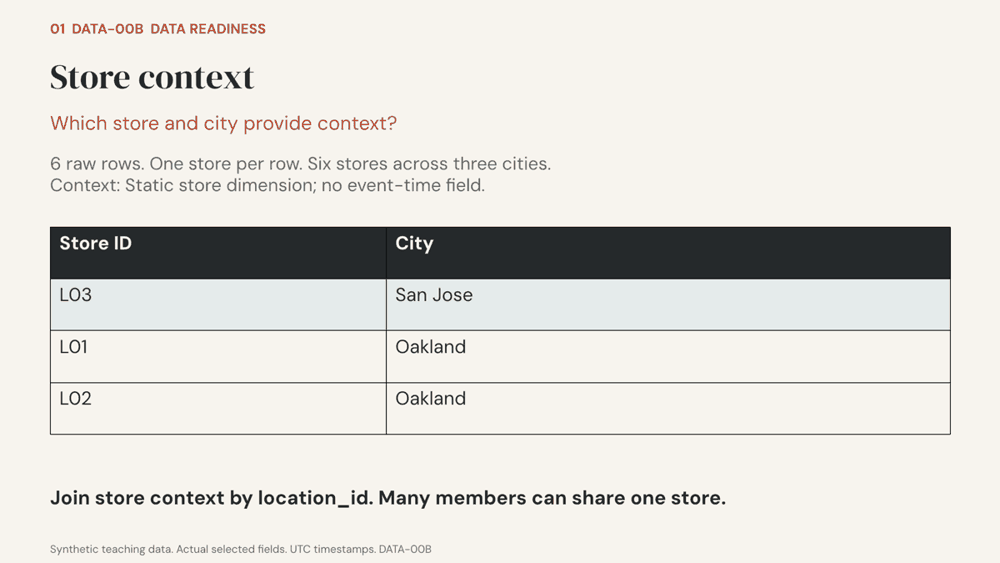

**What this means:** Join store context by location_id. Many members can share one store.

## DATA-00C — Campaign decisions and budgets

### The question
When does each decision occur?

### What to inspect
- 6 raw rows. One decision cohort per row. Contact and booking budgets are separate.
- Decision dates listed: 2025-01-01 to 2025-06-15 (includes planned cohorts).

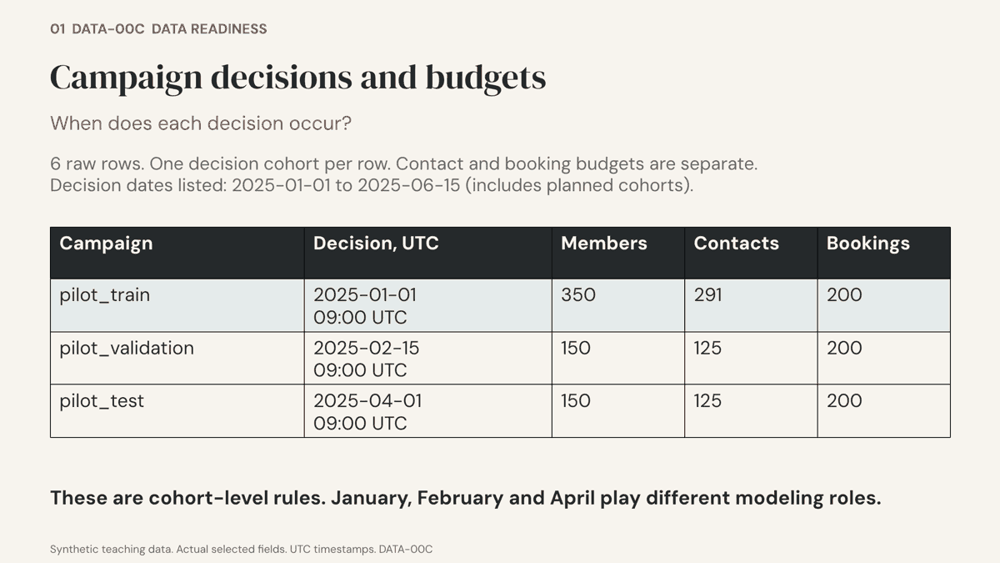

**What this means:** These are cohort-level rules. January, February and April play different modeling roles.

## DATA-00D — Behavior event records

### The question
What activity was available before the decision?

### What to inspect
- 40,268 raw rows. One activity event per row. The fixture supplies up to 90 days per decision.
- Event dates: 2024-10-03 to 2025-06-01.

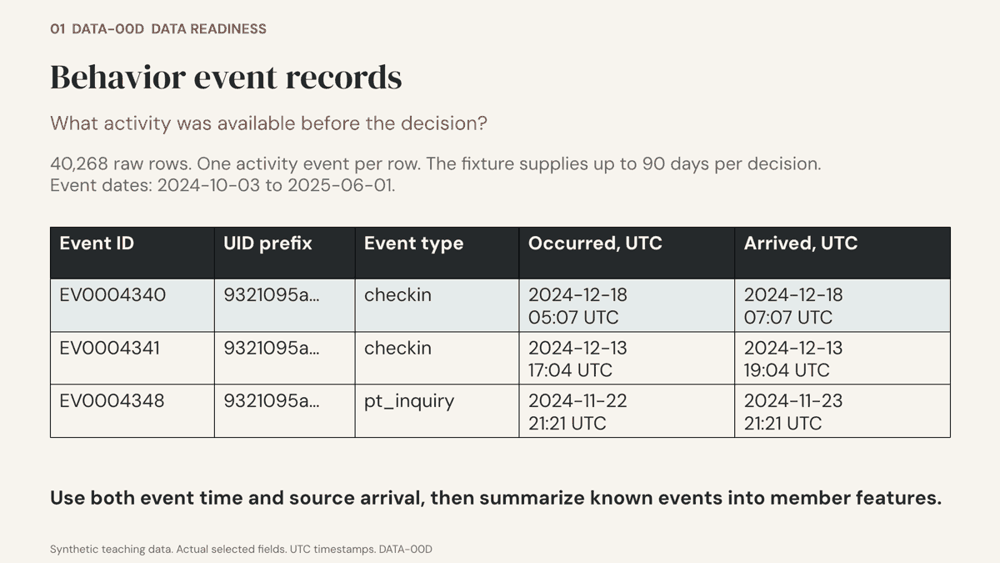

**What this means:** Use both event time and source arrival, then summarize known events into member features.

## DATA-00E — Promotion sending and delivery

### The question
What happened when the gym contacted a member?

### What to inspect
- 624 raw rows. One sending attempt per row. Sending and successful delivery differ.
- Sending dates: 2025-01-01 to 2025-05-20.

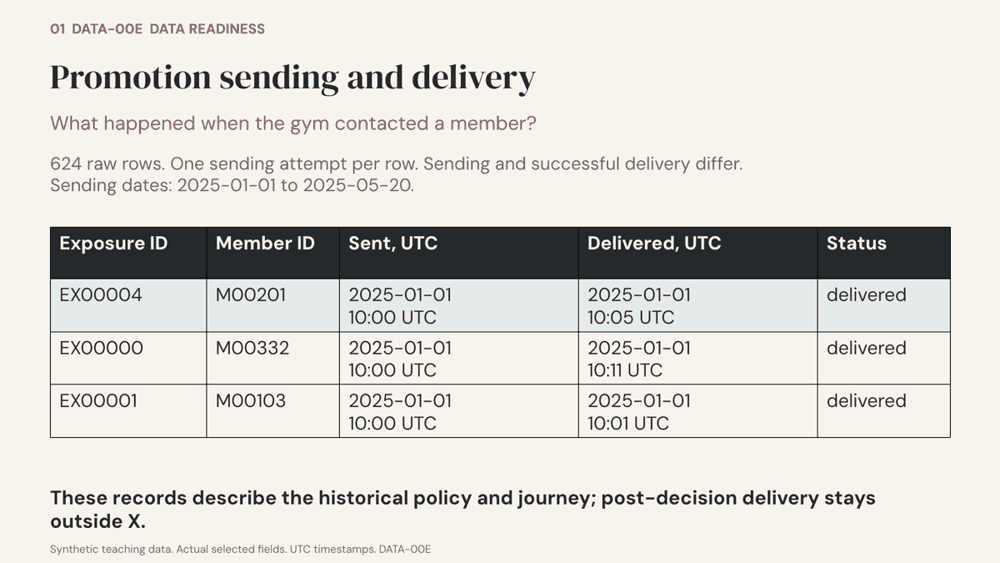

**What this means:** These records describe the historical policy and journey; post-decision delivery stays outside X.

## DATA-00F — Optional consultation records

### The question
Did a booking lead to a completed consultation?

### What to inspect
- 420 raw rows. One booking request per row. A completed consultation is an optional route.
- Request dates: 2025-01-01 to 2025-05-25.

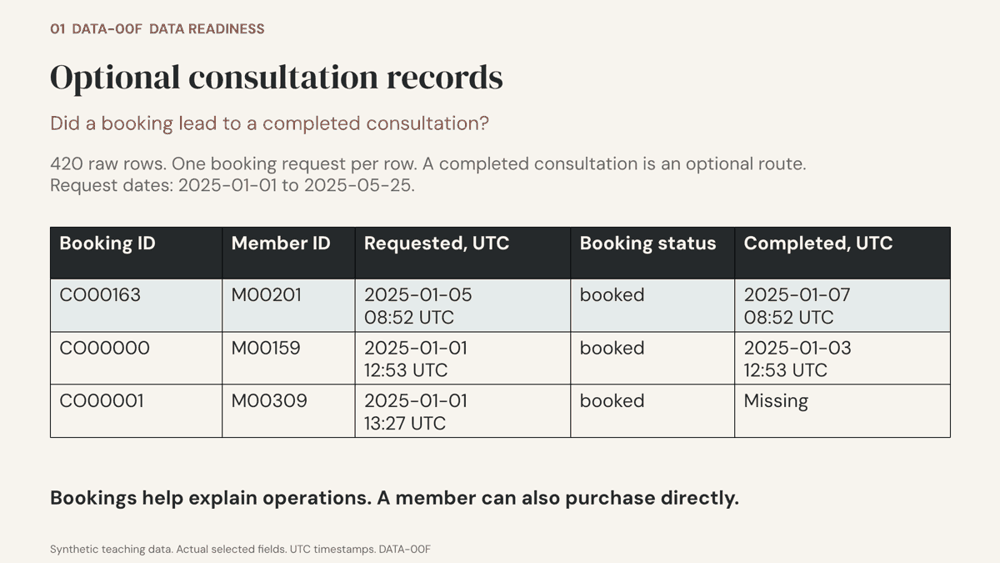

**What this means:** Bookings help explain operations. A member can also purchase directly.

## DATA-00G — New purchase and transaction-state records

### The question
Which later transaction states define a purchase outcome?

### What to inspect
- 178 raw rows. One order-state event per row. Multiple states can describe one transaction.
- State-event dates: 2025-01-02 to 2025-05-31.

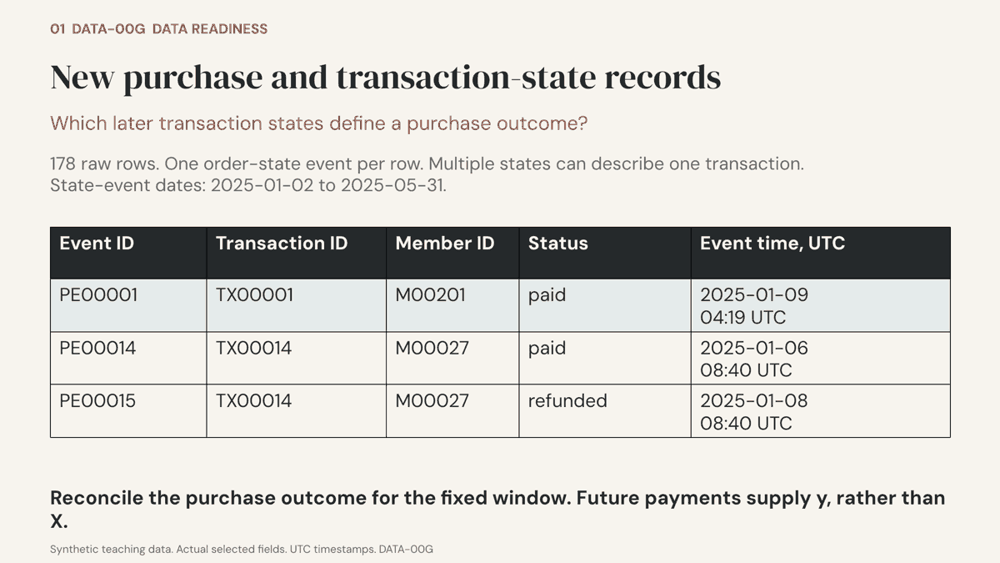

**What this means:** Reconcile the purchase outcome for the fixed window. Future payments supply y, rather than X.

## DATA-00H — Payment coverage checks

### The question
Can the payment source support a complete outcome?

### What to inspect
- 36 raw rows. One campaign/store coverage record. The exported check is dated June 1.
- Coverage-through dates: 2025-04-20 to 2025-06-01.

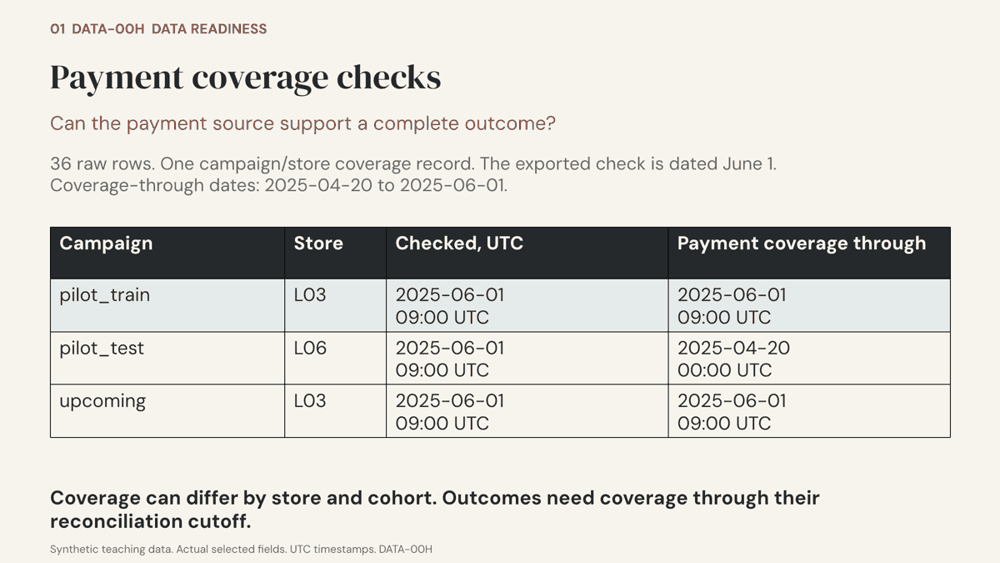

**What this means:** Coverage can differ by store and cohort. Outcomes need coverage through their reconciliation cutoff.

## DATA-00I — One member journey: M00201

### The question
How do those separate records describe the same person?

### What to inspect
- lapsed_pt member at L03. Decision: January 1, 2025.

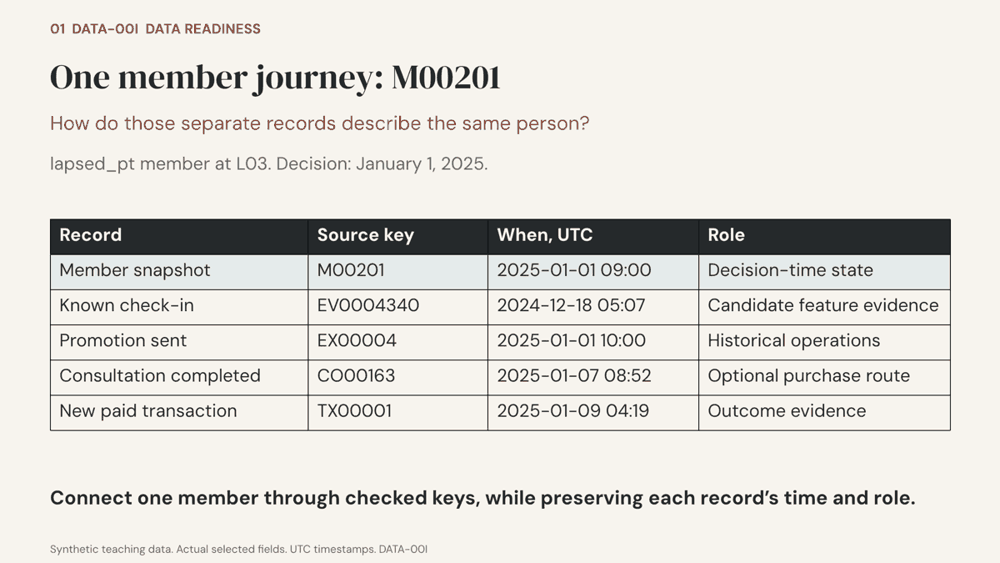

**What this means:** Connect one member through checked keys, while preserving each record’s time and role.

## DATA-00J — How the member-decision row takes shape

### The question
How do multiple event rows become one useful modeling example?

### What to inspect
- Worked example: M00201. The same rules later apply to the whole population.

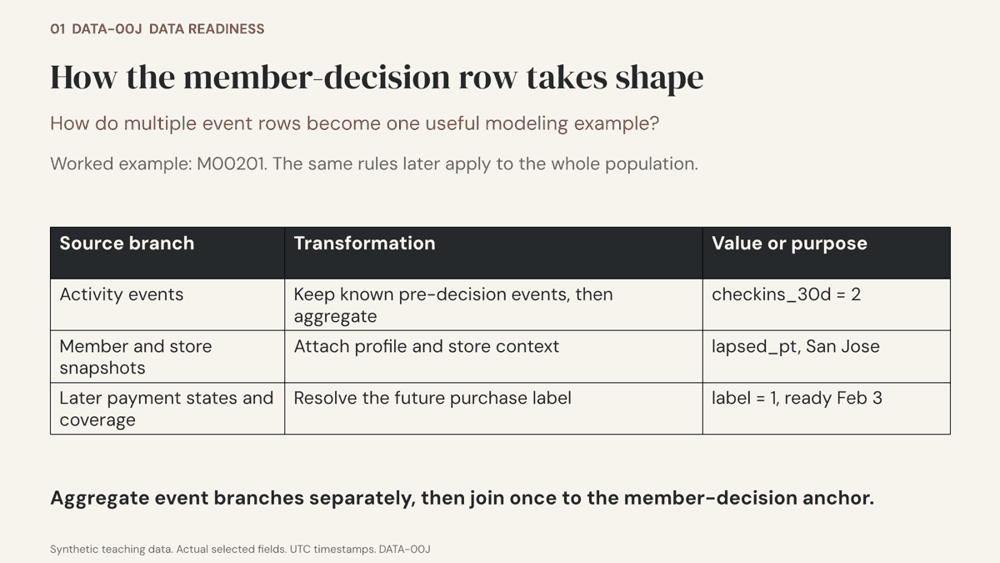

**What this means:** Aggregate event branches separately, then join once to the member-decision anchor.

**Join contract:** Activity UID maps to the unique member UID. Aggregate events before the one-to-one member join. Store context uses a many-to-one location join. Payment coverage uses campaign and store together. A payment-event key differs from a transaction key. Keep direct purchases when consultation ID is absent.

## DATA-00K — A preview of the modeling master table

### The question
What does one final analysis row contain?

### What to inspect
- One member, one decision time, known features and a later purchase label.

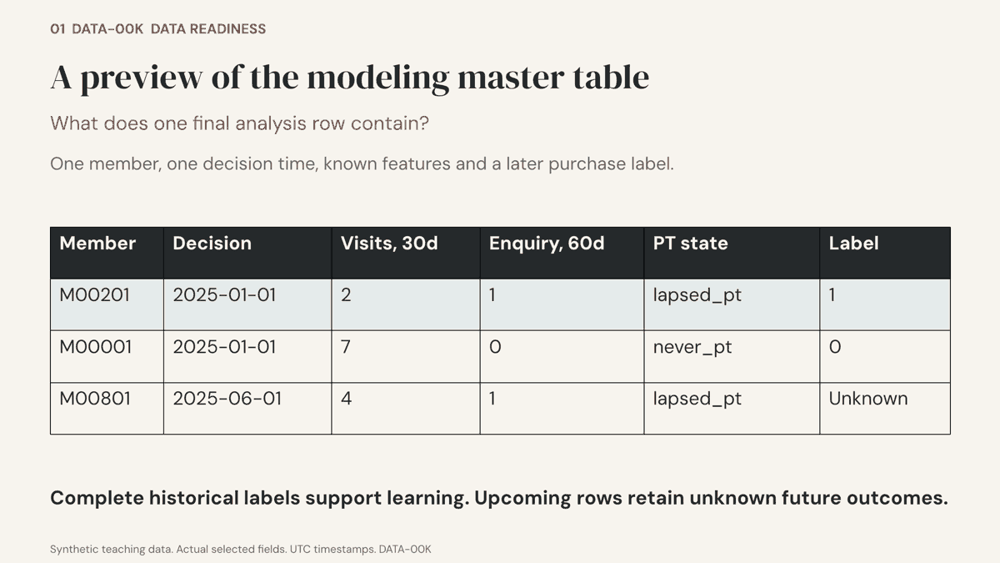

**What this means:** Complete historical labels support learning. Upcoming rows retain unknown future outcomes.

**Preview boundary:** This sample comes from the existing feature export. The actual batch computation remains in02 MOD-02. Labels describe later purchases; upcoming labels remain unknown.

## EDA-01 — Count people separately from events

### The question
How much data do we have, and what does one row represent?

### The plan
- Read the manifest and verify raw-file hashes.
- Parse timestamps in UTC.
- Count raw table rows separately from unique members and decision cohorts.

### What to look for
Compare the inventory with population counts. A visit/payment-state row is not a new member-decision example.

In [ ]:
# Import libraries for saved files, arrays, tables and inspection.
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# Input/output paths: notebooks run from Current beside gym_case_data.
DATA_DIR = Path('gym_case_data')


# Raw inputs are distinct from cleaned tables and derived modeling artifacts.
RAW_DIR = DATA_DIR / 'raw'
CLEAN_DIR = DATA_DIR / 'clean'
FIGURE_DIR = DATA_DIR / 'figures/module2'
CLEAN_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
assert (DATA_DIR / 'manifest.json').exists(), 'Run notebook 00 first, or transfer its gym_case_data folder here.'


# Record rules and file hashes so01 can verify the exact fixture.
manifest = json.loads((DATA_DIR / 'manifest.json').read_text())


# Use the extraction timestamp and target/reconciliation rules from the manifest.
AS_OF = pd.Timestamp(manifest['extracted_at'])


# Fixture parameters: version, random seed and business/label timing rules.
DATA_VERSION = manifest['data_version']
OUTCOME_WINDOW = pd.Timedelta(days=manifest['outcome_days'])
RECONCILIATION = pd.Timedelta(days=manifest['reconciliation_days'])
TRAIN_CAMPAIGN = 'pilot_train'
print('[INFO]', DATA_VERSION, '| extraction', AS_OF, '| outcome window', OUTCOME_WINDOW)


# Read each source only after checking its hash against the manifest.
raw = {}
for table_name, record in manifest['tables'].items():
    path = RAW_DIR / f'{table_name}.csv'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == record['sha256'], f'Changed raw file: {table_name}'
    raw[table_name] = pd.read_csv(path)
    for column in raw[table_name]:
        if column.endswith('_at') or column in ['decision_time', 'event_time', 'payments_complete_through']:
            raw[table_name][column] = pd.to_datetime(raw[table_name][column], utc=True, format="mixed")


# Keep chart styling consistent across evidence figures.
BLUE, GREEN, ORANGE, GRAY, RED = '#2166AC', '#287D65', '#C87919', '#6B7280', '#B43A45'
plt.rcParams.update({'font.size': 13, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white'})
figure_records = []


# Evidence helper: save each displayed figure with its exact CSV and population/version metadata.
def save_video_figure(figure, figure_id, question, population, evidence):
    """Save the displayed chart and the exact data behind it for Video 2 reuse."""
    evidence.to_csv(FIGURE_DIR / f'{figure_id}.csv', index=False)
    figure.text(.02, .015, f'{DATA_VERSION} | Synthetic teaching data | As of {AS_OF:%Y-%m-%d} UTC', fontsize=9, color=GRAY)
    figure.tight_layout(rect=(0, .05, 1, .96))
    figure.savefig(FIGURE_DIR / f'{figure_id}.png', dpi=150, facecolor='white')
    figure.savefig(FIGURE_DIR / f'{figure_id}.svg', facecolor='white')
    figure_records.append({'figure_id': figure_id, 'question': question, 'population': population,
                           'data_version': DATA_VERSION, 'as_of': AS_OF.isoformat(), 'source_csv': f'{figure_id}.csv'})
    plt.show()
    plt.close(figure)


# Document each source grain before comparing its row count.
row_grains = {'members': 'one person / first opportunity', 'locations': 'one store',
              'campaigns': 'one campaign', 'activity_events': 'one behavior event',
              'promotion_exposures': 'one sending attempt', 'consultations': 'one booking request',
              'payment_events': 'one order state event', 'source_health': 'one campaign/store watermark'}
inventory = pd.DataFrame([{'table': name, 'rows': len(table), 'grain': row_grains[name]} for name, table in raw.items()])
display(inventory)
fig, ax = plt.subplots(figsize=(12.8, 7.2))
bars = ax.barh(inventory.table, inventory.rows, color=BLUE)
ax.bar_label(bars, padding=7, fmt='%d'); ax.set_xlim(0, inventory.rows.max() * 1.2)
ax.set(title='How much source data do we have?', xlabel='Raw rows — different grains, not independent people')
save_video_figure(fig, 'M2_01_source_records', 'How much source data do we have?', 'All exported raw records; duplicates retained', inventory)


# Count unique members by decision cohort separately from event records.
members = raw['members'].copy()
population_counts = members.groupby('campaign_id', sort=False).agg(members=('member_id', 'nunique'), decision_time=('decision_time', 'first')).reset_index()
fig, ax = plt.subplots(figsize=(12.8, 7.2))
bars = ax.bar(population_counts.campaign_id.str.replace('pilot_', ''), population_counts.members,
              color=[BLUE, BLUE, BLUE, ORANGE, GRAY, GREEN])
ax.bar_label(bars, padding=6); ax.set_ylim(0, population_counts.members.max() * 1.18)
ax.set(title='Which people belong to which decision period?', ylabel='Unique members')
save_video_figure(fig, 'M2_02_population', 'How many people are historical or upcoming?', 'All 2,000 unique members; campaign snapshots, not cleaning losses', population_counts)

### Takeaway — EDA-01

**You now know the source grains and cohort sizes.** These counts establish inventory, not the number of complete training labels.

**Before moving on:** Explain how this output supports the next decision.

## EDA-02 — Repair records without removing business populations

### The question
Which defects should be repaired, and which missing values should remain?

### The plan
- Remove exact import duplicates and assert valid keys.
- Quarantine unresolved activity identities.
- Check member references and retain meaningful/profile missingness.
- Save the cleaned sources.

### What to look for
Read affected-row counts and identity diagnostics. These are repair categories, not an attrition funnel.

In [ ]:
# Expected primary keys: duplicates/conflicts are quality issues, not extra observations.
keys = {'members': 'member_id', 'locations': 'location_id', 'campaigns': 'campaign_id',
        'activity_events': 'event_id', 'promotion_exposures': 'exposure_id',
        'consultations': 'consultation_id', 'payment_events': 'payment_event_id'}


# Track repairs and missingness separately while preserving the intended populations.
clean, quality_rows = {}, []


# Remove exact duplicates and assert nonmissing/unique source keys.
for name, table in raw.items():
    clean[name] = table.drop_duplicates().copy()
    removed = len(table) - len(clean[name])
    if name in keys:
        assert clean[name][keys[name]].notna().all()
        assert clean[name][keys[name]].is_unique, f'Conflicting key in {name}'
    quality_rows.append({'check': f'{name}: duplicate rows', 'affected_rows': removed})
    print(f'[CHECK] Exact duplicate filter ({name}): {len(table)} to {len(clean[name])} records (dropped {removed})')
assert clean['members'].uid.is_unique


# Resolve event identities through a checked many-to-one bridge.
activity_join = clean['activity_events'].merge(clean['members'][['uid', 'member_id']], on='uid', how='left', validate='many_to_one', indicator=True)


# Quarantine unresolved events before they can contribute member features.
unmatched = activity_join._merge.eq('left_only')
print(f'[CHECK] Identity join: input {len(clean["activity_events"])}; output {len(activity_join)}; unmatched {unmatched.sum()}; duplicate bridge keys 0; missing member_id introduced {activity_join.member_id.isna().sum()}')
activity_join.loc[unmatched].to_csv(DATA_DIR / 'quarantined_activity.csv', index=False)
clean['activity_events'] = clean['activity_events'][~clean['activity_events'].uid.isin(activity_join.loc[unmatched, 'uid'])].copy()
quality_rows.append({'check': 'Unresolved activity identity', 'affected_rows': int(unmatched.sum())})


# Check member references in downstream operation/payment tables.
for name in ['promotion_exposures', 'consultations', 'payment_events']:
    assert clean[name].member_id.isin(clean['members'].member_id).all(), f'Unresolved member in {name}'
for column in ['plan_type', 'preferred_channel']:
    quality_rows.append({'check': f'Missing {column}', 'affected_rows': int(members[column].isna().sum())})


# Summarize affected source rows; different issues require different actions.
quality_report = pd.DataFrame(quality_rows)
visible_quality = quality_report[quality_report.affected_rows.gt(0)].copy()
fig, ax = plt.subplots(figsize=(12.8, 7.2))
bars = ax.barh(visible_quality['check'], visible_quality.affected_rows, color=ORANGE)
ax.bar_label(bars, padding=6); ax.set_xlim(0, visible_quality.affected_rows.max() * 1.2)
ax.set(title='Which data issues require different actions?', xlabel='Affected source rows — not a member attrition funnel')
save_video_figure(fig, 'M2_03_data_quality', 'What must be repaired or retained?', 'All source tables; preferences are retained, orphan events quarantined', visible_quality)


# Remove exact duplicates and assert nonmissing/unique source keys.
for name, table in clean.items():
    table.to_csv(CLEAN_DIR / f'{name}.csv', index=False)

### Takeaway — EDA-02

**Records are deduplicated and linked before aggregation.** Member eligibility and expected absence of prior PT dates remain intact.

**Before moving on:** Explain how this output supports the next decision.

## EDA-03 — Trace one route without assuming everyone follows it

### The question
How do multiple systems describe one member over time?

### The plan
- Select one illustrative historical consultation-assisted purchase.
- Connect its decision, delivery, booking and payment timestamps.
- Display its events and timeline.

### What to look for
This is an optional reference example. Other members purchase directly; the target definition covers both routes.

In [ ]:
# Choose one historical illustration, not a representative conversion estimate.
training_ids = members.loc[members.campaign_id.eq(TRAIN_CAMPAIGN), 'member_id']
example_id = clean['payment_events'].loc[clean['payment_events'].member_id.isin(training_ids) & clean['payment_events'].purchase_route.eq('consultation'), 'member_id'].iloc[0]


# Inspect one member across events, promotion, consultation and payment timestamps.
example_member = members.set_index('member_id').loc[example_id]
example_activity = clean['activity_events'].query('uid == @example_member.uid').copy()
example_exposure = clean['promotion_exposures'].query('member_id == @example_id').iloc[0]
example_consultation = clean['consultations'].query('member_id == @example_id').iloc[0]
example_payment = clean['payment_events'].query('member_id == @example_id and status == "paid"').iloc[0]


# Express timestamps relative to the same decision boundary.
journey = pd.DataFrame({'stage': ['Promotion decision', 'First delivery', 'Booking requested', 'Consultation completed', 'Payment recorded'],
                        'timestamp': [example_member.decision_time, example_exposure.delivered_at,
                                      example_consultation.requested_at, example_consultation.completed_at, example_payment.event_time]})
journey['days_from_decision'] = (journey.timestamp - example_member.decision_time).dt.total_seconds() / 86400
print(f'[RESULT] Example {example_id}: {len(example_activity)} activity rows; one member opportunity.')
display(example_activity.head()); display(journey)
fig, ax = plt.subplots(figsize=(12.8, 7.2))
ax.scatter(journey.days_from_decision, range(len(journey)), s=130, color=BLUE)
ax.set_yticks(range(len(journey)), journey.stage); ax.invert_yaxis()
ax.axvline(0, color=GRAY, linestyle='--'); ax.set_xlim(-.5, journey.days_from_decision.max() + 1.5)
for index, row in journey.iterrows():
    ax.annotate(row.timestamp.strftime('%b %d %H:%M'), (row.days_from_decision, index), xytext=(10, -5), textcoords='offset points', fontsize=11)
ax.set(title=f'One member, several systems: {example_id}', xlabel='Days from selection decision (UTC)')
save_video_figure(fig, 'M2_04_member_journey', 'How do raw records describe one member?', f'Illustrative paid training member {example_id}; not a representative conversion rate', journey)

### Takeaway — EDA-03

**The timeline makes one set of timestamps inspectable.** It is not the average journey or a required route for every purchase.

**Before moving on:** Explain how this output supports the next decision.

## EDA-04 — Build decision-aligned purchase labels for all eligible members

### The question
Which member decisions can receive reliable purchase labels?

### The plan
- Start the window at each member decision.
- Classify upcoming, planned, pending and incomplete sources explicitly.
- Reconcile transaction states at day 33.
- Assign1/0 only to complete outcomes and save observations.

### What to look for
Compare readiness reasons. Complete zero and unknown are different states; label eligibility does not depend on contact.

In [ ]:
# Attach promotion descriptors without requiring exposure for outcome eligibility.
exposures = clean['promotion_exposures']


# Keep every member snapshot; validate that the join does not multiply rows.
observations = members.merge(exposures[['member_id', 'sent_at', 'delivered_at', 'delivery_status']],
                             on='member_id', how='left', validate='one_to_one', indicator=True)
print(f'[CHECK] Exposure join: input {len(members)}; output {len(observations)}; no sending record {observations._merge.eq("left_only").sum()}; duplicate keys 0.')
print('[CHECK] Missing delivered_at includes unsent and failed delivery; report reasons below.')
observations = observations.drop(columns='_merge').merge(
    clean['source_health'], on=['campaign_id', 'location_id'], how='left', validate='many_to_one')
assert observations.checked_at.notna().all() and observations.checked_at.le(AS_OF).all()


# Define the future-purchase endpoint and reconciliation maturity for each decision.
observations['outcome_end'] = observations.decision_time + OUTCOME_WINDOW
observations['label_ready_at'] = observations.outcome_end + RECONCILIATION


# Contact and PT history are descriptors, never label-eligibility filters.
observations['label_status'] = np.select(
    [observations.campaign_id.eq('upcoming'), observations.decision_time.gt(AS_OF),
     observations.label_ready_at.gt(AS_OF), observations.payments_complete_through.lt(observations.label_ready_at)],
    ['upcoming_unlabeled', 'not_entered', 'pending', 'source_incomplete'], default='complete')
observations['label'] = np.nan


# Reconcile each mature exposed member using only the order states available by their fixed cutoff.
for row in observations.loc[observations.label_status.eq('complete')].itertuples(index=False):

    # Use transaction states available by label maturity, not later updates.
    member_payments = clean['payment_events'].loc[
        clean['payment_events'].member_id.eq(row.member_id)
        & clean['payment_events'].available_at.le(row.label_ready_at)
        & clean['payment_events'].event_time.le(row.label_ready_at)]

    # Keep the final visible state per transaction, then check validity and purchase window.
    latest_states = member_payments.sort_values(['event_time', 'payment_event_id']).drop_duplicates('transaction_id', keep='last')

    # Only valid PT purchases after decision and inside the outcome window make a positive.
    qualifying = latest_states.status.eq('paid') & latest_states.product_code.eq('four_session_pt')
    qualifying &= latest_states.event_time.gt(row.decision_time) & latest_states.event_time.le(row.outcome_end)
    observations.loc[observations.member_id.eq(row.member_id), 'label'] = int(qualifying.any())
assert observations.loc[observations.label_status.ne('complete'), 'label'].isna().all()
assert observations.member_id.is_unique
observations.to_csv(DATA_DIR / 'observations.csv', index=False)


# Show readiness categories with member counts and save evidence for review.
status_counts = observations.loc[observations.campaign_id.ne('upcoming'), 'label_status'].value_counts().rename_axis('status').reset_index(name='members')
fig, ax = plt.subplots(figsize=(12.8, 7.2))
bars = ax.barh(status_counts.status.str.replace('_', ' '), status_counts.members,
               color=[GREEN if value == 'complete' else ORANGE for value in status_counts.status])
ax.bar_label(bars, padding=6); ax.set_xlim(0, status_counts.members.max() * 1.18)
ax.set(title='Which historical outcomes are actually known?', xlabel='Members across 800 historical / planned opportunities')
save_video_figure(fig, 'M2_05_outcome_readiness', 'Which outcomes are complete, pending or unavailable?', '800 historical/planned members; excludes the 1,200 upcoming members', status_counts)
readiness_by_campaign = observations.groupby(['campaign_id', 'label_status']).size().rename('members').reset_index()
display(readiness_by_campaign)

### Takeaway — EDA-04

**The observation table has a defined future-purchase target and explicit readiness.** Only complete labels can enter supervised fitting.

**Before moving on:** Explain how this output supports the next decision.

## EDA-05 — Separate marketing activity from all purchase routes

### The question
How do promotion and consultation counts relate to all purchase outcomes?

### The plan
- Count stages in the January training campaign.
- Include valid direct purchases in the total buyer count.
- Separate the consultation disposition categories.

### What to look for
Optional business-process reference: the final purchase count is not necessarily a subset of completed consultations.

In [ ]:
# Use January members consistently; contact/consultation are descriptive operations.
training_population = observations.loc[observations.campaign_id.eq(TRAIN_CAMPAIGN)].copy()
training_eligible = training_population.loc[training_population.label_status.eq('complete')].copy()


# All complete members contribute outcomes, regardless of promotion delivery or PT history.
training_delivered = training_population.loc[training_population.delivered_at.notna()].copy()
assert training_eligible.label_status.eq('complete').all()
training_consultations = clean['consultations'].loc[clean['consultations'].campaign_id.eq(TRAIN_CAMPAIGN)]
assert training_consultations.member_id.is_unique


# Stage counts are not one required nested route; final purchases include all valid paths.
funnel = pd.DataFrame({'stage': ['Eligible', 'Selected / sent', 'Delivered', 'Requested booking', 'Accepted booking', 'Completed consultation', 'Any valid purchase (all routes)'],
                       'members': [len(training_population), int(training_population.sent_at.notna().sum()), len(training_delivered),
                                   len(training_consultations), int(training_consultations.booking_status.eq('booked').sum()),
                                   int(training_consultations.completed_at.notna().sum()), int(training_eligible.label.sum())]})


# Purchases can bypass consultation: the final stage is not a nested funnel count.
funnel['share_of_eligible'] = funnel.members / len(training_population)
display(funnel)
fig, ax = plt.subplots(figsize=(12.8, 7.2))
bars = ax.barh(funnel.stage, funnel.members, color=[GRAY, BLUE, BLUE, ORANGE, ORANGE, GREEN, GREEN])
ax.invert_yaxis(); ax.bar_label(bars, padding=7); ax.set_xlim(0, funnel.members.max() * 1.18)
ax.set(title='What happened after the January promotion?', xlabel=f'Members in the same training campaign; eligible denominator = {len(training_population)}; stages are not all nested')
save_video_figure(fig, 'M2_06_campaign_funnel', 'Where do members leave the campaign journey?', 'January training campaign only; final purchases require complete reconciled labels', funnel)

booked_count = int(training_consultations.booking_status.eq('booked').sum())
completed_count = int(training_consultations.completed_at.notna().sum())


# Keep unserved capacity, attendance and non-requesting categories distinguishable.
disposition = pd.DataFrame({'reason': ['No recorded request', 'Request blocked: capacity full', 'Booked, not completed', 'Consultation completed'],
                            'members': [len(training_delivered) - len(training_consultations),
                                        int(training_consultations.booking_status.eq('capacity_closed').sum()),
                                        booked_count - completed_count, completed_count]})
assert disposition.members.sum() == len(training_delivered)
fig, ax = plt.subplots(figsize=(12.8, 7.2))
bars = ax.barh(disposition.reason, disposition.members, color=[GRAY, RED, ORANGE, GREEN])
ax.invert_yaxis(); ax.bar_label(bars, padding=7); ax.set_xlim(0, disposition.members.max() * 1.2)
ax.set(title='A missed consultation can have different causes', xlabel='Delivered training members — mutually exclusive outcomes')
save_video_figure(fig, 'M2_07_consultation_disposition', 'Was the barrier demand, capacity or attendance?', 'All delivered January training members; categories sum to the delivered denominator', disposition)

### Takeaway — EDA-05

**Operations and outcomes use different denominators.** Keep purchase as the prediction target and appointment capacity as a separate operational rule.

**Before moving on:** Explain how this output supports the next decision.

## EDA-06 — Check what information was really available

### The question
Was a historical event actually usable at the decision?

### The plan
- Attach each training member decision to its activity.
- Compute event-time and arrival-time distances from the decision.
- Identify past events that arrived too late.

### What to look for
Read the two-clock plot: occurred before decision AND available by decision are both required.

In [ ]:
# Attach decision time to events so availability can be audited independently.
training_bridge = members.loc[members.campaign_id.eq(TRAIN_CAMPAIGN), ['uid', 'decision_time']]
clock_audit = clean['activity_events'].merge(training_bridge, on='uid', validate='many_to_one')


# Show occurrence and source arrival relative to the decision in days.
clock_audit['event_days'] = (clock_audit.event_time - clock_audit.decision_time).dt.total_seconds() / 86400
clock_audit['arrival_days'] = (clock_audit.available_at - clock_audit.decision_time).dt.total_seconds() / 86400
clock_audit['known_at_decision'] = clock_audit.event_days.lt(0) & clock_audit.arrival_days.le(0)
print('[CHECK] All training events:', clock_audit.known_at_decision.value_counts().to_dict())
clock_display = clock_audit.loc[clock_audit.event_days.between(-6, 0)].copy()
fig, ax = plt.subplots(figsize=(12.8, 7.2))


# Plot events known at decision against those that arrived too late.
for known, color, label in [(True, BLUE, 'Known at decision'), (False, ORANGE, 'Arrived too late')]:
    group = clock_display.loc[clock_display.known_at_decision.eq(known)]
    ax.scatter(group.event_days, group.arrival_days, color=color, label=label, alpha=.65, s=38)
ax.axhline(0, color=GRAY, linestyle='--'); ax.axvline(0, color=GRAY, linestyle='--')
ax.set(title='A past event may still be unavailable at selection', xlabel='Event time: days from decision', ylabel='Arrival time: days from decision')
ax.legend()
save_video_figure(fig, 'M2_08_two_clocks', 'What information was really available?', 'Training behavior events occurring in the six days before selection', clock_display[['event_id', 'event_days', 'arrival_days', 'known_at_decision']])

### Takeaway — EDA-06

**A historical timestamp alone is not enough.** The same two-clock filter must precede feature aggregation.

**Before moving on:** Explain how this output supports the next decision.

## EDA-07 — Inspect the target distribution in the training population

### The question
How much positive training evidence is ready?

### The plan
- Use all complete January labels, across contact/PT groups.
- Count valid new buyers and non-buyers.
- Display the imbalance and the purchase rate.

### What to look for
Inspect76 buyers versus274 non-buyers, rather than interpreting raw activity volume as training support.

In [ ]:
# Training-only target evidence: count new buyers and genuine complete zeros.
training_labels = training_eligible.label.astype(int)
class_balance = training_labels.value_counts().reindex([0, 1], fill_value=0).rename_axis('label').reset_index(name='members')
class_balance['outcome'] = ['No valid purchase', 'Any valid purchase (all routes)']
fig, ax = plt.subplots(figsize=(12.8, 7.2))
bars = ax.bar(class_balance.outcome, class_balance.members, color=[GRAY, GREEN])
ax.bar_label(bars, padding=8); ax.set_ylim(0, class_balance.members.max() * 1.2)
ax.set(title='How many purchase examples can training use?', ylabel='Complete eligible January members, all PT histories')
save_video_figure(fig, 'M2_09_training_outcomes', 'How much positive evidence is available?', 'Complete eligible training members; all PT relationships; training labels only', class_balance)
print(f'[RESULT] Training purchase rate: {training_labels.sum()} / {len(training_labels)} = {training_labels.mean():.1%}')

### Takeaway — EDA-07

**Training has350 complete examples.** The smaller positive group and support counts matter when interpreting later ranking comparisons.

**Before moving on:** Explain how this output supports the next decision.

## EDA-08 — Check recent activity and coverage across PT relationships

### The question
Does candidate information cover the intended members and show plausible training signal?

### The plan
- Compare store and plan representation with the upcoming population.
- Inspect the historical staff selection pattern.
- Compare training outcomes across PT relationships.
- Build a point-in-time recent-activity view for buyers/non-buyers.
- Display a compact training feature-check table linking the four candidate families to the spoken findings.

### What to look for
Read support counts and denominators. Use these descriptive checks to justify candidates, then compare representations in modeling.

In [ ]:
# Reserve future outcomes; use unlabeled profiles only for population/coverage or scoring.
upcoming = observations.loc[observations.campaign_id.eq('upcoming')].copy()


# Compare support across historical and upcoming profiles without exploring upcoming labels.
profile_comparison = pd.concat([training_eligible.assign(population='Training eligible'), upcoming.assign(population='Upcoming eligible')])
coverage = pd.crosstab(profile_comparison.location_id, profile_comparison.population).reset_index()
fig, ax = plt.subplots(figsize=(12.8, 7.2))
coverage.set_index('location_id').plot.bar(ax=ax, color=[GREEN, BLUE], rot=0)
ax.set(title='Are the same stores represented?', xlabel='Store', ylabel='Members (different population sizes)')
save_video_figure(fig, 'M2_10_store_coverage', 'Which stores are represented in learning and scoring?', 'Complete eligible training versus all upcoming eligible members; counts, not outcome rates', coverage)


# Compare plan shares, preserving missing categories in the population view.
plan_profile = pd.crosstab(profile_comparison.plan_type.fillna('Missing'), profile_comparison.population, normalize='columns').reset_index()
fig, ax = plt.subplots(figsize=(12.8, 7.2))
plan_profile.set_index('plan_type').plot.bar(ax=ax, color=[GREEN, BLUE], rot=0)
ax.set(title='Does membership composition change?', xlabel='Membership plan', ylabel='Share within each population')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.0%}'))
save_video_figure(fig, 'M2_11_population_mix', 'Does history resemble the next campaign?', 'Within-population plan shares; missing plans retained', plan_profile)

training_activity = clean['activity_events'].merge(training_bridge, on='uid', validate='many_to_one')


# Reconstruct the enquiry signal with both clocks and the60-day window.
known_enquiries = training_activity.loc[training_activity.event_type.eq('pt_inquiry')
    & training_activity.event_time.lt(training_activity.decision_time)
    & training_activity.available_at.le(training_activity.decision_time)
    & training_activity.event_time.ge(training_activity.decision_time - pd.Timedelta(days=60)), 'uid']


# Inspect the staff contact policy descriptively, not as a causal purchase effect.
selection_audit = training_population.assign(prior_enquiry=training_population.uid.isin(known_enquiries),
                                             selected=training_population.sent_at.notna())
selection_summary = selection_audit.groupby('prior_enquiry').agg(eligible=('member_id', 'size'), selected=('selected', 'sum')).reset_index()
selection_summary['selection_rate'] = selection_summary.selected / selection_summary.eligible
fig, ax = plt.subplots(figsize=(12.8, 7.2))
bars = ax.bar(['No known enquiry', 'Known enquiry'], selection_summary.selection_rate, color=BLUE)
ax.bar_label(bars, labels=[f'{row.selected}/{row.eligible}' for row in selection_summary.itertuples()], padding=7)
ax.set_ylim(0, 1.15); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.0%}'))
ax.set(title='Did staff choose some members more often?', ylabel='Share selected within enquiry group')
save_video_figure(fig, 'M2_12_historical_selection', 'How did the old selection policy shape the evidence?', 'All eligible January members; contact selection, not purchase or causal effect', selection_summary)


# PT history is a feature, never an exclusion. Only TRAINING labels are inspected here.
relationship = training_eligible.groupby('pt_relationship').agg(members=('member_id','size'), buyers=('label','sum')).reindex(['never_pt','active_pt','lapsed_pt']).reset_index()
relationship['purchase_rate'] = relationship.buyers / relationship.members
assert relationship.members.gt(0).all()
fig, ax = plt.subplots(figsize=(12.8, 7.2))
bars = ax.bar(relationship.pt_relationship, relationship.purchase_rate, color=[BLUE,GREEN,ORANGE])
ax.bar_label(bars, labels=[f'{int(row.buyers)}/{int(row.members)} buyers' for row in relationship.itertuples()], padding=6)
ax.set(title='First purchase, repeat purchase and reactivation all belong', ylabel='Training purchase rate; descriptive, not a causal effect', ylim=(0,max(.4,relationship.purchase_rate.max()*1.3)))
save_video_figure(fig,'M2_13_pt_relationship','Do all PT histories belong in the learning population?','Complete eligible training members; no PT-history exclusion',relationship)


# A pre-decision engagement view keeps EDA grounded in the proposed feature set.
activity_profiles = []


# Aggregate each member from only their known pre-decision activity.
for person in training_eligible.itertuples(index=False):
    events = clean['activity_events'].loc[clean['activity_events'].uid.eq(person.uid)]
    known = events.loc[events.event_time.lt(person.decision_time) & events.available_at.le(person.decision_time)]
    visits = known.loc[known.event_type.eq('checkin') & known.event_time.ge(person.decision_time-pd.Timedelta(days=30))]
    activity_profiles.append({'member_id':person.member_id,'pt_relationship':person.pt_relationship,'checkins_30d':len(visits),'label':int(person.label)})


# Build a point-in-time30-day check-in view for the training comparison.
activity_profiles = pd.DataFrame(activity_profiles)
fig, ax = plt.subplots(figsize=(12.8, 7.2))
for label,color in [(0,BLUE),(1,GREEN)]:
    ax.hist(activity_profiles.loc[activity_profiles.label.eq(label),'checkins_30d'],bins=np.arange(0,50,3),alpha=.55,label=f'Target {label}',color=color)
ax.legend(); ax.set(title='Recent engagement is available for buyers and non-buyers',xlabel='Known check-ins in the 30 days before decision',ylabel='Training members')
save_video_figure(fig,'M2_14_recent_activity','What recent engagement could support prediction?','Training only; fixed pre-decision time and availability cutoff',activity_profiles)


# Put the training-only feature checks beside the figures for recording and learner inspection.
feature_check = pd.DataFrame([
    {'family': 'Recent engagement',
     'training evidence': f"Check-ins: buyers {activity_profiles.loc[activity_profiles.label.eq(1), 'checkins_30d'].mean():.2f}; non-buyers {activity_profiles.loc[activity_profiles.label.eq(0), 'checkins_30d'].mean():.2f}",
     'interpretation': 'Plausible candidate signal; compare combined inputs later'},
    {'family': 'Prior PT history',
     'training evidence': f"{training_eligible.pt_relationship.nunique()} relationships; {training_eligible.last_pt_purchase_at.isna().sum()} absent prior-purchase dates",
     'interpretation': 'Preserve never-buyer history and meaningful missingness'},
    {'family': 'Member profile',
     'training evidence': f"Missing plan: {training_eligible.plan_type.isna().sum()}; missing channel: {training_eligible.preferred_channel.isna().sum()}",
     'interpretation': 'Retain members; fit missing-value handling in training'},
    {'family': 'Store / context',
     'training evidence': f"{training_eligible.location_id.nunique()} represented stores; {len(training_eligible)} complete training members",
     'interpretation': 'Review representation against the upcoming population'}
])
print('[RESULT] Training-only candidate feature checks:')
display(feature_check)

### Takeaway — EDA-08

**The four candidate families are reasonable to test.** Associations and coverage do not identify a final best feature subset or a causal effect.

**Before moving on:** Explain how this output supports the next decision.

## EDA-09 — State what the evidence can support

### The question
What exactly is ready to hand to modeling?

### The plan
- Summarize inventory, label readiness and training support.
- Save the evidence summary and figure manifest.
- Connect cleaned sources and observations to notebook 02.

### What to look for
Check the population, timing and limits against the saved evidence, not just the number of charts.

### Evidence from the current fixture
**Our finding:** We can create 625 complete historical observations across separate modeling cohorts. The training cohort has **350 observations, 76 buyers and 274 non-buyers (21.7% positive)**. There are 40,268 raw activity rows, but those are not independent modeling examples.

**All PT relationships are represented:**

| Relationship at decision | Training members | New buyers |
|---|---|---|
| active_pt | 103 | 21 |
| lapsed_pt | 93 | 22 |
| never_pt | 154 | 33 |

**Readiness:** Historical states are {'complete': 625, 'pending': 100, 'not_entered': 50, 'source_incomplete': 25}. Unknown outcomes stay out of training; no exclusion depends on PT history or message delivery. The full set of 625 observations must not all be used for training: later cohorts are reserved for validation/test.

**Business process:** The training campaign recorded 197 accepted consultations and 76 valid purchasers across all routes. These are different populations; consultation capacity cannot be interpreted as a cap on PT sales.

**Sufficiency judgment:** Adequate for a limited synthetic-data comparison of modest models and the staff rule; insufficient for a reliable launch, stable subgroup probabilities or a claim of incremental long-term PT sales. Positive counts remain small, one later store has incomplete payment coverage, and the fixture contains disjoint member snapshots rather than repeated campaign histories. The generator defines a learnable teaching process, not real-world evidence.

In [ ]:
# Record population, readiness and support counts for a traceable modeling handoff.
evidence_summary = {'data_version': DATA_VERSION, 'as_of': AS_OF.isoformat(),
                    'raw_activity_rows': len(raw['activity_events']), 'unique_members': len(members),
                    'historical_and_planned_members': int(members.campaign_id.ne('upcoming').sum()),
                    'upcoming_members': len(upcoming), 'historical_status_counts': dict(zip(status_counts.status, status_counts.members.astype(int))),
                    'training_complete_eligible': len(training_eligible), 'training_buyers': int(training_labels.sum()),
                    'training_purchase_rate': float(training_labels.mean()),
                    'training_pt_relationships': training_eligible.groupby('pt_relationship').agg(members=('member_id','size'), buyers=('label','sum')).reset_index().to_dict('records'),
                    'upcoming_pt_relationships': upcoming.pt_relationship.value_counts().to_dict(),
                    'training_funnel': dict(zip(funnel.stage, funnel.members.astype(int))),
                    'training_disposition': dict(zip(disposition.reason, disposition.members.astype(int))),
                    'no_model_or_incremental_effect_claim': True}
(DATA_DIR / 'evidence_summary.json').write_text(json.dumps(evidence_summary, indent=2))
(FIGURE_DIR / 'figure_manifest.json').write_text(json.dumps(figure_records, indent=2))
display(pd.Series(evidence_summary, name='Evidence'))
print('[RESULT] Saved cleaned tables, observations, and 14 Video 2 figures with CSV evidence.')

### Takeaway — EDA-09

**The lab supports a bounded synthetic modeling comparison.** The handoff is clean sources plus decision-aligned observations;02 constructs the candidate matrix.

**Before moving on:** Explain how this output supports the next decision.